In [ ]:

import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

df = pd.read_csv(url, header=None, names=columns)

# Remove empty rows
df.dropna(how="all", inplace=True)

# Display first five rows
print("First five rows:")
print(df.head())

#with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    #print(df)

# Count records
print("\nTotal records:", len(df))

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Class distribution
print("\nClass distribution:")
print(df["species"].value_counts())


First five rows:
   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

Total records: 150

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class distribution:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Separate input features (X) and target (y)
X = df.iloc[:, :-1]
y = df["species"]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 120
Testing records: 30


In [ ]:

import numpy as np

# Convert training data into NumPy arrays
X_train_np = X_train.to_numpy()
X_test_np = X_test.to_numpy()
y_train_np = y_train.to_numpy()

# Step 1: Calculate prior probabilities, means, and variances
classes = np.unique(y_train_np)
model = {}

for c in classes:
    # Select records belonging to this species
    X_c = X_train_np[y_train_np == c]

    # Prior probability: P(class)
    prior = len(X_c) / len(X_train_np)

    # Mean and variance of each feature
    mean = np.mean(X_c, axis=0)
    variance = np.var(X_c, axis=0)

    # Prevent division by zero
    variance = np.maximum(variance, 1e-9)

    model[c] = {
        "prior": prior,
        "mean": mean,
        "variance": variance
    }

# Step 2: Gaussian probability formula
def gaussian_probability(x, mean, variance):
    exponent = np.exp(-((x - mean) ** 2) / (2 * variance))
    denominator = np.sqrt(2 * np.pi * variance)
    return exponent / denominator

# Step 3: Predict the species of one flower
def predict_one(x):
    scores = {}

    for c in classes:
        prior = model[c]["prior"]
        mean = model[c]["mean"]
        variance = model[c]["variance"]

        # Start with the prior probability
        score = np.log(prior)

        # Add log probabilities of all four features
        probabilities = gaussian_probability(x, mean, variance)
        score += np.sum(np.log(probabilities))

        scores[c] = score

    return max(scores, key=scores.get)

# Step 4: Predict all test flowers
y_pred = np.array([predict_one(x) for x in X_test_np])

print("Class prior probabilities:")
for c in classes:
    print(c, ":", model[c]["prior"])

print("\nFirst 10 predictions:")
for actual, predicted in zip(y_test.to_numpy()[:10], y_pred[:10]):
    print("Actual:", actual, "| Predicted:", predicted)


Class prior probabilities:
Iris-setosa : 0.3333333333333333
Iris-versicolor : 0.3333333333333333
Iris-virginica : 0.3333333333333333

First 10 predictions:
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-virginica | Predicted: Iris-virginica
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-versicolor | Predicted: Iris-versicolor
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-setosa | Predicted: Iris-setosa
Actual: Iris-virginica | Predicted: Iris-virginica
Actual: Iris-versicolor | Predicted: Iris-versicolor


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Compare actual labels with predicted labels
y_actual = y_test.to_numpy()

# Calculate evaluation metrics
accuracy = accuracy_score(y_actual, y_pred)
precision = precision_score(y_actual, y_pred, average="macro")
recall = recall_score(y_actual, y_pred, average="macro")
f1 = f1_score(y_actual, y_pred, average="macro")
cm = confusion_matrix(y_actual, y_pred, labels=classes)

# Display results
print("Accuracy:", accuracy)
print("Macro Precision:", precision)
print("Macro Recall:", recall)
print("Macro F1-score:", f1)

print("\nConfusion Matrix:")
print(cm)


Accuracy: 0.9666666666666667
Macro Precision: 0.9696969696969697
Macro Recall: 0.9666666666666667
Macro F1-score: 0.9665831244778612

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


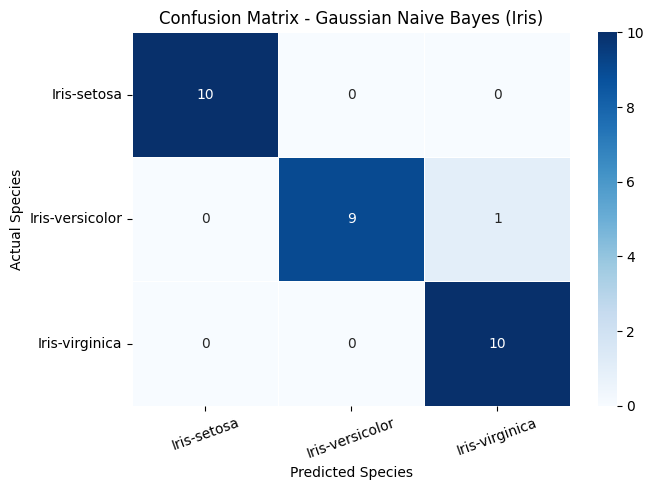

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    cbar=True,
    linewidths=0.5,
    linecolor="white"
)
plt.title("Confusion Matrix - Gaussian Naive Bayes (Iris)")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("confusion_matrix_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

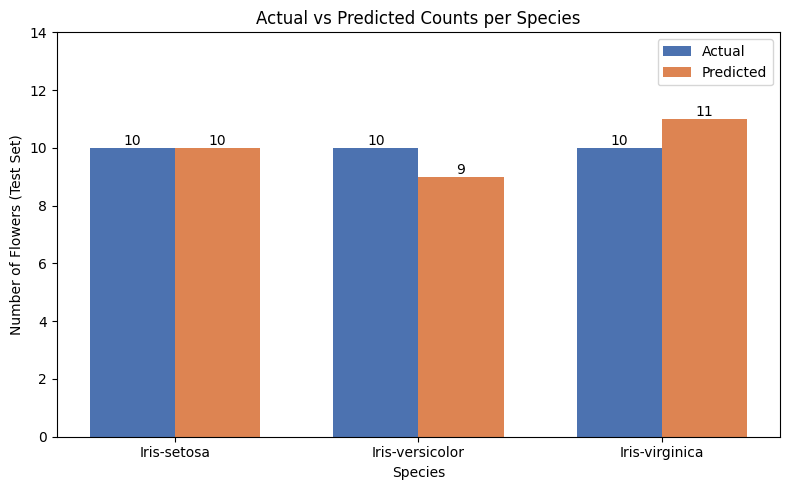

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Count how many flowers of each species are actual vs predicted
actual_counts = pd.Series(y_actual).value_counts().reindex(classes, fill_value=0)
predicted_counts = pd.Series(y_pred).value_counts().reindex(classes, fill_value=0)

x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, actual_counts.values, width, label="Actual", color="#4C72B0")
bars2 = ax.bar(x + width/2, predicted_counts.values, width, label="Predicted", color="#DD8452")

# Show the count on top of each bar
for bars in (bars1, bars2):
    for bar in bars:
        ax.annotate(
            int(bar.get_height()),
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center", va="bottom", fontsize=10
        )

ax.set_title("Actual vs Predicted Counts per Species")
ax.set_xlabel("Species")
ax.set_ylabel("Number of Flowers (Test Set)")
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0, max(actual_counts.max(), predicted_counts.max()) + 3)
ax.legend()
plt.tight_layout()
plt.savefig("actual_vs_predicted_bar_chart.png", dpi=300, bbox_inches="tight")
plt.show()